# 03 · Quanto vale ogni domanda? La lunghezza ottimale del test

Un Taste Test deve riconoscere il Carattere di una persona con il minor numero di domande possibile. Ogni domanda in più costa utenti che abbandonano. Quante domande servono, e quali?

**20 domande possibili**:
- **19 domande di gusto**: "questo dolce ti dà gioia o delusione?", su dolci *diversi* da quelli che definiscono il profilo;
- **1 domanda demografica**: l'età, l'unica domanda non legata al gusto che ha senso in un Taste Test (notebook 01).

Il bersaglio è il Carattere del notebook 02, misurato su altri 38 dolci. Il test deve quindi indovinare il gusto di una persona su prodotti che **non le ha chiesto**.

**Approccio.**
1. Misuro il valore di ogni domanda da sola.
2. Aggiungo una domanda alla volta, sempre la più utile (*forward selection*), e misuro su persone **mai viste** quanto migliora il test, con intervalli di confidenza e test statistici.
3. Confronto l'ordine ottimizzato con domande scelte a caso, e il test fisso con un test **adattivo**.
4. Traduco il risultato in una lunghezza ottimale, tenendo conto dell'abbandono.

In [2]:
%pip install statsmodels

   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ----------- ---------------------------- 3.1/11.3 MB 16.3 MB/s eta 0:00:01
   -------------------------- ------------- 7.6/11.3 MB 18.8 MB/s eta 0:00:01
   ---------------------------------------- 11.3/11.3 MB 18.7 MB/s  0:00:00

   -------- ------------------------------- 1/5 [patsy]
   -------- ------------------------------- 1/5 [patsy]
   ------------------------ --------------- 3/5 [formulaic]
   ------------------------ --------------- 3/5 [formulaic]
   -------------------------------- ------- 4/5 [statsmodels]
   -------------------------------- ------- 4/5 [statsmodels]
   -------------------------------- ------- 4/5 [statsmodels]
   -------------------------------- ------- 4/5 [statsmodels]
   -------------------------------- ------- 4/5 [statsmodels]
   -------------------------------- ------- 4/5 [statsmodels]
   -------------------------------- ------- 4/5 [statsmodels]
   ----------------------------

In [3]:
import json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, StratifiedKFold, RepeatedStratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, log_loss, confusion_matrix
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from statsmodels.stats.contingency_tables import mcnemar
from stile_grafici import applica_stile, salva, BLU, ARANCIO, ACQUA, GIALLO, GRIGIO, GRIGIO_CHIARO, TESTO_2

warnings.filterwarnings("ignore", category=FutureWarning)
applica_stile()
SEED = 42

M = pd.read_csv("../data/processed/valutazioni_2015.csv", index_col="persona")
ctx = pd.read_csv("../data/processed/contesto_2015.csv", index_col="persona")
profili = pd.read_csv("../data/processed/profili_2015.csv", index_col="persona")["carattere"]
divisione = json.load(open("../data/processed/divisione_catalogo.json"))
PROFILO, DOMANDE_GUSTO = divisione["profilo"], divisione["domande"]
NOMI = ["#Goloso", "#Vivace", "#Eccentrico", "#Fresco", "#Morbido"]
y = profili.loc[M.index].map({n: i for i, n in enumerate(NOMI)}).to_numpy()

CONTESTO = {"eta": "Età"}

# Ogni domanda = un gruppo di colonne one-hot. Per i dolci: gioia / delusione / non risposto
def codifica_gusto(serie):
    testo = serie.map({1.0: "gioia", 0.0: "delusione"}).fillna("non_risposto")
    return pd.get_dummies(testo, prefix=serie.name).astype(int)

BLOCCHI = {d: codifica_gusto(M[d]) for d in DOMANDE_GUSTO}
for c in CONTESTO:
    BLOCCHI[c] = pd.get_dummies(ctx.loc[M.index, c], prefix=c).astype(int)
ETICHETTE = {**{d: d for d in DOMANDE_GUSTO}, **CONTESTO}
TIPO = {**{d: "gusto" for d in DOMANDE_GUSTO}, **{c: "contesto" for c in CONTESTO}}
X_tutto = pd.concat(BLOCCHI.values(), axis=1)

def colonne_di(domande):
    return [c for q in domande for c in BLOCCHI[q].columns]

print(f"Persone: {len(M):,} · Domande possibili: {len(BLOCCHI)} ({len(DOMANDE_GUSTO)} di gusto, {len(CONTESTO)} di contesto)")
print("Profili:", pd.Series(y).map(dict(enumerate(NOMI))).value_counts().reindex(NOMI).to_dict())

Persone: 4,579 · Domande possibili: 20 (19 di gusto, 1 di contesto)
Profili: {'#Goloso': 1020, '#Vivace': 742, '#Eccentrico': 721, '#Fresco': 1176, '#Morbido': 920}


## 1. Impostazione della valutazione

- **Train/test 80/20, stratificato per profilo.** Ordine delle domande e regolarizzazione si scelgono *solo* sul train. Il test (circa 920 persone) serve una volta sola, per misurare.
- **Modello:** regressione logistica multinomiale regolarizzata. Più avanti verifico che un modello più flessibile non cambi le conclusioni.
- **Metriche:**
  - *accuratezza*, cioè la quota di persone a cui il test assegna il Carattere giusto
  - *log loss*, più sensibile, per scegliere le domande.
- **Punto di partenza (0 domande):** assegnare a tutti il profilo più comune, #Fresco, al 26% circa.

In [4]:
idx_tr, idx_te = train_test_split(np.arange(len(y)), test_size=0.2, stratify=y, random_state=SEED)
y_tr, y_te = y[idx_tr], y[idx_te]
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
TUTTE = list(BLOCCHI)

for C_ in [0.03, 0.1, 0.3, 1]:
    ll = cross_val_score(LogisticRegression(C=C_, max_iter=3000), X_tutto.iloc[idx_tr], y_tr, cv=cv, scoring="neg_log_loss").mean()
    print(f"C = {C_:<5} log loss CV = {-ll:.4f}")
C = 0.1

maggioritario = np.bincount(y_tr).argmax()
acc_base = (y_te == maggioritario).mean()
print(f"\nNessuna domanda (tutti {NOMI[maggioritario]}): accuratezza sul test = {acc_base:.1%}")

C = 0.03  log loss CV = 1.3320
C = 0.1   log loss CV = 1.3308
C = 0.3   log loss CV = 1.3354
C = 1     log loss CV = 1.3403

Nessuna domanda (tutti #Fresco): accuratezza sul test = 25.7%


## 2. Quanto vale ogni domanda *da sola*?

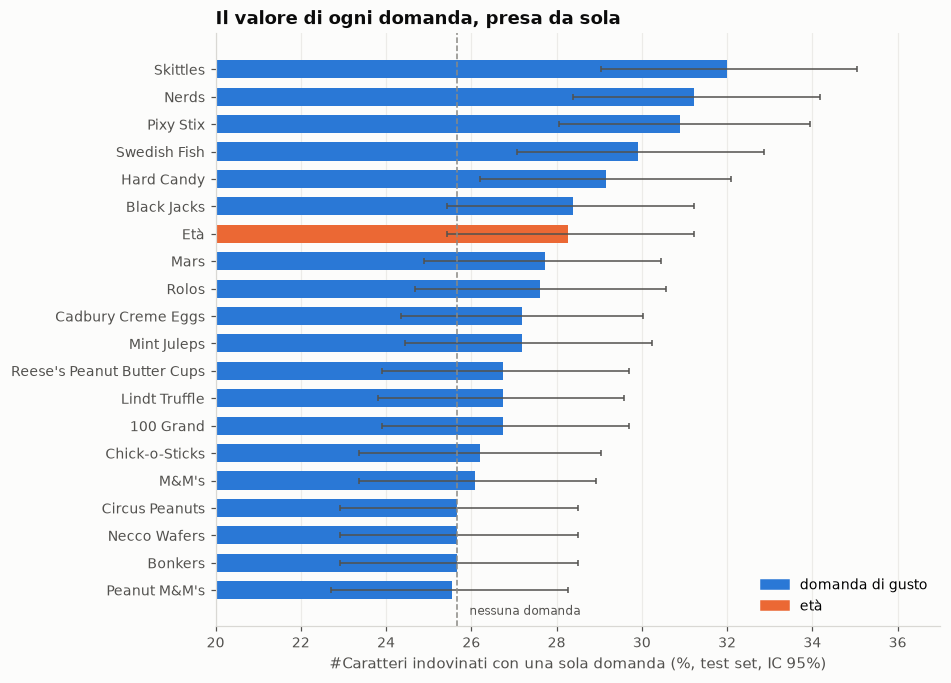

,tipo,accuratezza,ic_basso,ic_alto
Skittles,gusto,0.320,0.290,0.350
Nerds,gusto,0.312,0.284,0.342
Pixy Stix,gusto,0.309,0.281,0.340
Swedish Fish,gusto,0.299,0.271,0.329
Hard Candy,gusto,0.291,0.262,0.321
Black Jacks,gusto,0.284,0.254,0.312
eta,contesto,0.283,0.254,0.312
Mars,gusto,0.277,0.249,0.305
Rolos,gusto,0.276,0.247,0.306
Cadbury Creme Eggs,gusto,0.272,0.243,0.300


In [5]:
rng = np.random.default_rng(SEED)
BOOT = 2000
boot_idx = [rng.integers(0, len(y_te), len(y_te)) for _ in range(BOOT)]

def modello(domande):
    cols = colonne_di(domande)
    return LogisticRegression(C=C, max_iter=3000).fit(X_tutto.iloc[idx_tr][cols], y_tr), cols

def valuta(domande):
    m, cols = modello(domande)
    proba = m.predict_proba(X_tutto.iloc[idx_te][cols])
    pred = proba.argmax(axis=1)
    corretto = pred == y_te
    boot = [corretto[i].mean() for i in boot_idx]
    return {"accuratezza": corretto.mean(), "ic_basso": np.percentile(boot, 2.5), "ic_alto": np.percentile(boot, 97.5),
            "log_loss": log_loss(y_te, proba, labels=range(5)), "pred": pred, "proba": proba}

singole = pd.DataFrame({q: {k: v for k, v in valuta([q]).items() if k not in ("pred", "proba")} for q in TUTTE}).T.astype(float)
singole["tipo"] = [TIPO[q] for q in singole.index]
singole = singole.sort_values("accuratezza")

fig, ax = plt.subplots(figsize=(8.5, 7))
pos = np.arange(len(singole))
colori = [BLU if t == "gusto" else ARANCIO for t in singole["tipo"]]
ax.barh(pos, singole["accuratezza"] * 100, color=colori, height=0.66)
ax.errorbar(singole["accuratezza"] * 100, pos,
            xerr=[(singole["accuratezza"] - singole["ic_basso"]) * 100, (singole["ic_alto"] - singole["accuratezza"]) * 100],
            fmt="none", ecolor="#52514e", elinewidth=1, capsize=2)
ax.axvline(acc_base * 100, color=GRIGIO, linestyle="--", linewidth=1)
ax.text(acc_base * 100 + 0.3, -0.9, "nessuna domanda", fontsize=8, color=TESTO_2)
ax.set_yticks(pos, [ETICHETTE[q] for q in singole.index])
ax.set_xlabel("#Caratteri indovinati con una sola domanda (%, test set, IC 95%)")
ax.set_title("Il valore di ogni domanda, presa da sola")
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_xlim(20, 37)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=BLU), plt.Rectangle((0, 0), 1, 1, color=ARANCIO)],
          labels=["domanda di gusto", "età"], loc="lower right")
salva(fig, "03_valore_singole_domande")
plt.show()
singole[["tipo", "accuratezza", "ic_basso", "ic_alto"]].iloc[::-1].round(3)

Tre risultati:

- **Le domande più utili riguardano i dolci fruttati** (Skittles, Nerds, Pixy Stix, Swedish Fish). Da sole portano i profili indovinati dal 26% a circa il 30–32%. Il motivo: la frutta è la dimensione che separa di più i gusti, perché è opposta al cioccolato (notebook 02).
- **Chiedere un dolce che piace a quasi tutti serve a poco.** Reese's, M&M's e Peanut M&M's piacciono all'80–90% delle persone, quindi la risposta non distingue nessuno. Una buona domanda divide il pubblico.
- **L'età porta un po' di informazione** (28%), ma vale quanto una domanda di gusto mediocre. Sei domande di gusto da sole fanno meglio.

## 3. La curva: accuratezza in funzione del numero di domande

Aggiungo le domande una alla volta. A ogni passo scelgo, **in cross-validation sul train**, quella che migliora di più il test già costruito.

In [6]:
def ll_cv(domande):
    cols = colonne_di(domande)
    return -cross_val_score(LogisticRegression(C=C, max_iter=3000), X_tutto.iloc[idx_tr][cols], y_tr,
                            cv=cv, scoring="neg_log_loss").mean()

ordine, restanti = [], list(TUTTE)
while restanti:
    migliore = min(restanti, key=lambda q: ll_cv(ordine + [q]))
    ordine.append(migliore); restanti.remove(migliore)
print("Ordine scelto:\n" + "\n".join(f"{i + 1:>2}. {ETICHETTE[q]}" + ("   [contesto]" if TIPO[q] == "contesto" else "")
                                    for i, q in enumerate(ordine)))
json.dump({"ordine": ordine, "C": C}, open("../data/processed/ordine_domande_2015.json", "w"))

Ordine scelto:
 1. Nerds
 2. 100 Grand
 3. Black Jacks
 4. Hard Candy
 5. Peanut M&M's
 6. Skittles
 7. Mars
 8. Necco Wafers
 9. Rolos
10. Swedish Fish
11. Pixy Stix
12. Cadbury Creme Eggs
13. Mint Juleps
14. Età   [contesto]
15. Reese's Peanut Butter Cups
16. M&M's
17. Lindt Truffle
18. Chick-o-Sticks
19. Bonkers
20. Circus Peanuts


In [7]:
passi = {k: valuta(ordine[:k]) for k in range(1, len(ordine) + 1)}
K = len(ordine)

def mcnemar_p(pred_a, pred_b):
    a, b = pred_a == y_te, pred_b == y_te
    return mcnemar([[np.sum(a & b), np.sum(a & ~b)], [np.sum(~a & b), np.sum(~a & ~b)]], exact=True).pvalue

curva = pd.DataFrame({k: {"domanda_aggiunta": ETICHETTE[ordine[k - 1]], "accuratezza": v["accuratezza"],
                          "ic_basso": v["ic_basso"], "ic_alto": v["ic_alto"], "log_loss": v["log_loss"]}
                      for k, v in passi.items()}).T
for c in ["accuratezza", "ic_basso", "ic_alto", "log_loss"]:
    curva[c] = curva[c].astype(float)
curva["p_vs_completo"] = [mcnemar_p(passi[k]["pred"], passi[K]["pred"]) for k in curva.index]
curva["p_vs_precedente"] = [np.nan] + [mcnemar_p(passi[k]["pred"], passi[k - 1]["pred"]) for k in curva.index[1:]]
curva.round(3)

,domanda_aggiunta,accuratezza,ic_basso,ic_alto,log_loss,p_vs_completo,p_vs_precedente
1,Nerds,0.312,0.284,0.342,1.555,0.000,NaN
2,100 Grand,0.335,0.306,0.366,1.510,0.000,0.073
3,Black Jacks,0.343,0.314,0.373,1.482,0.000,0.621
4,Hard Candy,0.356,0.326,0.385,1.461,0.000,0.162
5,Peanut M&M's,0.364,0.333,0.396,1.447,0.000,0.450
6,Skittles,0.385,0.353,0.416,1.432,0.006,0.038
7,Mars,0.398,0.368,0.429,1.411,0.044,0.188
8,Necco Wafers,0.400,0.368,0.431,1.403,0.054,1.000
9,Rolos,0.408,0.377,0.440,1.397,0.143,0.512
10,Swedish Fish,0.405,0.372,0.436,1.386,0.081,0.836


Il test set ha circa 920 persone, quindi gli intervalli di confidenza sono di circa ±3 punti. Per una stima più precisa della forma della curva ripeto il calcolo con una **cross-validation ripetuta sul train** (5 fold × 5 ripetizioni). Aggiungo anche il confronto più importante: **quanto vale scegliere bene le domande?** Per questo calcolo la stessa curva con le domande in **ordine casuale**, mediando su 30 ordini diversi.

In [8]:
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED)
cv_rip = pd.DataFrame([{"k": k, **dict(zip(["media", "dev"], (lambda s: (s.mean(), s.std()))(
    cross_val_score(LogisticRegression(C=C, max_iter=3000), X_tutto.iloc[idx_tr][colonne_di(ordine[:k])], y_tr, cv=rcv))))}
    for k in range(1, K + 1)]).set_index("k")

casuali = []
rng_ord = np.random.default_rng(SEED)
for r in range(30):
    perm = list(rng_ord.permutation(TUTTE))
    casuali.append([accuracy_score(y_te, modello(perm[:k])[0].predict(X_tutto.iloc[idx_te][colonne_di(perm[:k])]))
                    for k in range(1, K + 1)])
casuali = pd.DataFrame(casuali, columns=range(1, K + 1))
print("Ordine casuale, accuratezza media:", casuali.mean().round(3).to_dict())

Ordine casuale, accuratezza media: {1: 0.279, 2: 0.297, 3: 0.311, 4: 0.325, 5: 0.336, 6: 0.351, 7: 0.363, 8: 0.368, 9: 0.371, 10: 0.381, 11: 0.389, 12: 0.397, 13: 0.401, 14: 0.405, 15: 0.41, 16: 0.414, 17: 0.417, 18: 0.423, 19: 0.423, 20: 0.431}


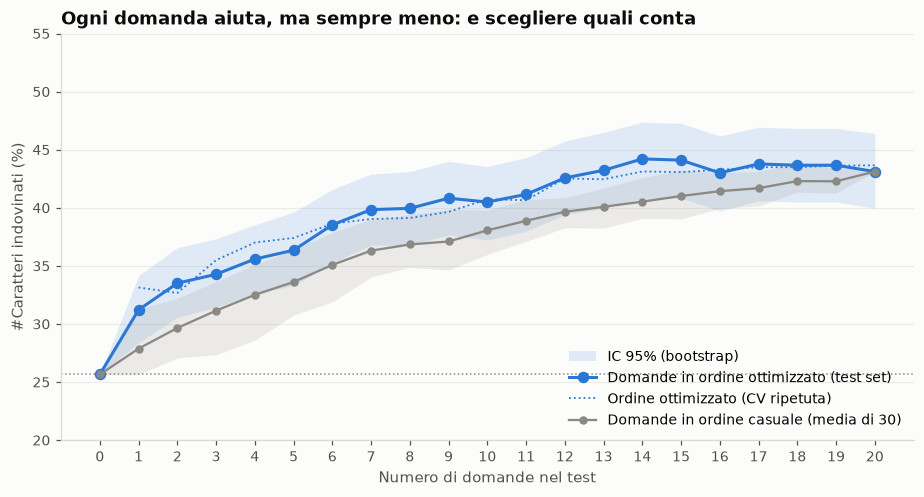

In [9]:
fig, ax = plt.subplots(figsize=(10, 4.8))
k_ax = np.arange(0, K + 1)
acc = np.r_[acc_base, curva["accuratezza"]]
lo, hi = np.r_[acc_base, curva["ic_basso"]], np.r_[acc_base, curva["ic_alto"]]
ax.fill_between(k_ax, lo * 100, hi * 100, color=BLU, alpha=0.13, linewidth=0, label="IC 95% (bootstrap)")
ax.plot(k_ax, acc * 100, marker="o", color=BLU, markersize=6.5, label="Domande in ordine ottimizzato (test set)")
ax.plot(cv_rip.index, cv_rip["media"] * 100, color=BLU, linewidth=1.2, linestyle=":", label="Ordine ottimizzato (CV ripetuta)")
cas_m = np.r_[acc_base, casuali.mean()]
cas_lo = np.r_[acc_base, casuali.quantile(0.1)]; cas_hi = np.r_[acc_base, casuali.quantile(0.9)]
ax.fill_between(k_ax, cas_lo * 100, cas_hi * 100, color=GRIGIO, alpha=0.15, linewidth=0)
ax.plot(k_ax, cas_m * 100, marker="o", color=GRIGIO, markersize=4.5, linewidth=1.5, label="Domande in ordine casuale (media di 30)")
ax.axhline(acc_base * 100, color=GRIGIO, linestyle=":", linewidth=1)
ax.set_xticks(k_ax)
ax.set_xlabel("Numero di domande nel test"); ax.set_ylabel("#Caratteri indovinati (%)")
ax.set_ylim(20, 55)
ax.set_title("Ogni domanda aiuta, ma sempre meno: e scegliere quali conta")
ax.legend(loc="lower right")
salva(fig, "03_curva_domande_accuratezza")
plt.show()

**Il risultato centrale del progetto.**

- **La curva sale in modo graduale e poi si appiattisce.** La prima domanda porta dal 26% al 31%; con 7 domande si arriva al 40%; tra 12 e 14 domande al 43–44%. Dopo, le 6 domande restanti non aggiungono più nulla: la log loss smette di migliorare e l'accuratezza oscilla nel rumore.
- **Scegliere quali domande fare vale quanto farne il doppio.** Con 7 domande scelte bene si arriva al 40%; con domande scelte a caso servono circa 13 domande per ottenere lo stesso risultato. Le due curve si ricongiungono solo quando si fanno *tutte* le domande.
- **L'età entra solo come 14ª domanda**, dopo 13 domande di gusto. Per profilare il gusto, una domanda sul gusto vale molto più di una domanda demografica.

### Dove si trova il "gomito"?

Lo definisco in modo esplicito, con due criteri:
1. **Criterio statistico:** il test più corto che **non è significativamente peggiore** del test completo con tutte e 20 le domande (McNemar, p > 0,05 da lì in poi).
2. **Criterio di rendimento:** il test più corto che raggiunge il **90% del guadagno** del test completo rispetto a "nessuna domanda", calcolato sulla CV ripetuta, più stabile.

In [10]:
non_peggiori = curva.index[curva["p_vs_completo"] > 0.05]
gomito_stat = next(k for k in curva.index if all(j in non_peggiori for j in range(k, K + 1)))

acc_cv = pd.Series(np.r_[acc_base, cv_rip["media"].values], index=range(0, K + 1))
guadagno = (acc_cv - acc_base) / (acc_cv.max() - acc_base)
gomito_90 = int(guadagno[guadagno >= 0.9].index.min())

print(f"Criterio statistico: dalla domanda {gomito_stat} in poi il test non è significativamente peggiore del test completo")
print(f"Criterio del 90%:    {gomito_90} domande raggiungono il 90% del guadagno massimo")
print(f"\nCon {gomito_90} domande: {acc_cv[gomito_90]:.1%} (CV) contro {acc_cv.max():.1%} del massimo e {acc_base:.1%} senza domande")
pd.DataFrame({"accuratezza (CV, %)": acc_cv * 100, "% del guadagno massimo": guadagno * 100}).round(1).T

Criterio statistico: dalla domanda 8 in poi il test non è significativamente peggiore del test completo
Criterio del 90%:    12 domande raggiungono il 90% del guadagno massimo

Con 12 domande: 42.5% (CV) contro 43.7% del massimo e 25.7% senza domande


,0,1,2,3,4,5,6,7,8,9,...,11,12,13,14,15,16,17,18,19,20
"accuratezza (CV, %)",25.7,33.1,32.7,35.5,37.0,37.4,38.6,39.0,39.1,39.7,...,40.7,42.5,42.5,43.1,43.1,43.3,43.5,43.5,43.6,43.7
% del guadagno massimo,0.0,41.6,39.0,54.7,63.1,65.3,72.1,74.3,74.8,77.7,...,83.3,93.7,93.3,97.0,96.8,97.8,99.1,99.1,99.8,100.0


I due criteri indicano una **finestra tra 8 e 12 domande**:

- **Dalla 8ª domanda in poi** il test non è più significativamente peggiore del test completo. Con le circa 920 persone del test set, differenze di 3 punti o meno non sono distinguibili dal caso.
- **Con 12 domande** si ottiene il 90% del guadagno possibile.

### Il limite non dipende dal modello

Il plateau potrebbe essere un limite della regressione logistica. Verifico con un *gradient boosting*, che cattura interazioni tra le risposte (per esempio "ama Reese's **e** odia Skittles").

In [11]:
hgb = HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=300, random_state=SEED)
hgb.fit(X_tutto.iloc[idx_tr], y_tr)
acc_hgb = accuracy_score(y_te, hgb.predict(X_tutto.iloc[idx_te]))
print(f"Logistica, {K} domande:         {curva.loc[K, 'accuratezza']:.1%}")
print(f"Gradient boosting, {K} domande: {acc_hgb:.1%}")

Logistica, 20 domande:         43.1%
Gradient boosting, 20 domande: 42.2%


I due modelli arrivano allo stesso livello, anzi il gradient boosting fa leggermente peggio: il plateau dipende dall'**informazione contenuta nelle domande**, non dal modello.

## 4. Un secondo modo di misurare: il test sa consigliare prodotti?

Un Taste Test non serve solo a dare un'etichetta, ma a **consigliare prodotti**. Misuro quindi anche se il test distingue, per ciascuno dei 38 dolci del profilo (mai chiesti), **chi lo amerà da chi no**.

La metrica è l'**AUC media per prodotto**. Per ogni dolce si prendono a caso una persona a cui piace e una a cui non piace: l'AUC è la probabilità che il test assegni alla prima una probabilità di gradimento più alta.
- **0,5** corrisponde al caso. È anche il valore del "consiglio per popolarità", che dice la stessa cosa a tutti e quindi non personalizza.
- **1** è una distinzione perfetta.

Confronto due modi di usare le risposte:
1. **Attraverso il Carattere**: il gradimento previsto è la media dei gradimenti dei 5 profili, pesata con la probabilità di appartenere a ciascuno.
2. **Direttamente**: per ogni dolce, un modello che prevede il gradimento dalle risposte, senza passare dal profilo.

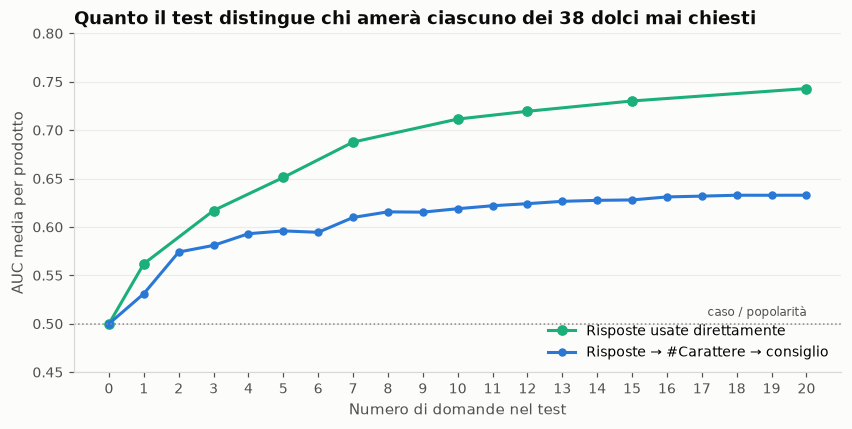

,0,1,3,5,7,10,12,15,20
tramite #Carattere,0.5,0.531,0.581,0.596,0.610,0.619,0.624,0.628,0.633
diretto,0.5,0.562,0.617,0.651,0.688,0.711,0.720,0.730,0.743


In [12]:
from sklearn.metrics import roc_auc_score
veri = M.iloc[idx_te][PROFILO].to_numpy()
gioia_per_profilo = np.vstack([M.iloc[idx_tr][PROFILO][y_tr == c].mean().to_numpy() for c in range(5)])

def auc_medio(p_gioia):
    aucs = []
    for j in range(veri.shape[1]):
        v = ~np.isnan(veri[:, j])
        if 0 < veri[v, j].mean() < 1:
            aucs.append(roc_auc_score(veri[v, j], p_gioia[v, j]))
    return np.mean(aucs)

def p_diretta(k):
    cols = colonne_di(ordine[:k])
    Xtr, Xte = X_tutto.iloc[idx_tr][cols], X_tutto.iloc[idx_te][cols]
    P = np.full(veri.shape, np.nan)
    for j, d in enumerate(PROFILO):
        yy = M.iloc[idx_tr][d]; v = yy.notna().to_numpy()
        P[:, j] = LogisticRegression(C=C, max_iter=3000).fit(Xtr[v], yy[v].astype(int)).predict_proba(Xte)[:, 1]
    return P

auc_profilo = pd.Series({0: 0.5, **{k: auc_medio(passi[k]["proba"] @ gioia_per_profilo) for k in range(1, K + 1)}})
k_diretti = sorted({1, 3, 5, 7, 10, 12, 15, K})
auc_diretto = pd.Series({0: 0.5, **{k: auc_medio(p_diretta(k)) for k in k_diretti}})

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(auc_diretto.index, auc_diretto.values, marker="o", color=ACQUA, markersize=6, label="Risposte usate direttamente")
ax.plot(auc_profilo.index, auc_profilo.values, marker="o", color=BLU, markersize=4.5, label="Risposte → #Carattere → consiglio")
ax.axhline(0.5, color=GRIGIO, linestyle=":", linewidth=1)
ax.text(K, 0.505, "caso / popolarità", ha="right", va="bottom", fontsize=8, color=TESTO_2)
ax.set_xticks(range(0, K + 1)); ax.set_ylim(0.45, 0.8)
ax.set_xlabel("Numero di domande nel test"); ax.set_ylabel("AUC media per prodotto")
ax.set_title("Quanto il test distingue chi amerà ciascuno dei 38 dolci mai chiesti")
ax.legend(loc="lower right")
salva(fig, "03_consigli_auc")
plt.show()
pd.DataFrame({"tramite #Carattere": auc_profilo, "diretto": auc_diretto}).loc[[0] + k_diretti].round(3).T

Due risultati:

1. **Le domande personalizzano davvero i consigli.** Con 12 domande l'AUC sale da 0,5 (popolarità) a circa 0,72: il test distingue chi amerà un dolce mai chiesto da chi no, ben oltre il caso.
2. **Passare dal #Carattere costa informazione.** Con le stesse risposte, i consigli dedotti dal profilo si fermano a circa 0,62–0,63, mentre il modello diretto arriva a 0,74. Il profilo comprime ogni persona in 5 categorie e così perde le sfumature individuali.

Per il business significa che **il Carattere e la raccomandazione sono due strumenti diversi**. Il Carattere serve a *comunicare* (un nome, una descrizione, un segmento per il marketing). Per *consigliare* prodotti conviene usare le risposte direttamente.

Con il modello diretto, inoltre, ogni domanda continua ad aiutare più a lungo: la curva non si appiattisce a 12 domande. Domande che non cambiano più il profilo assegnato migliorano ancora la precisione dei consigli.

## 5. Chi viene riconosciuto e chi no?

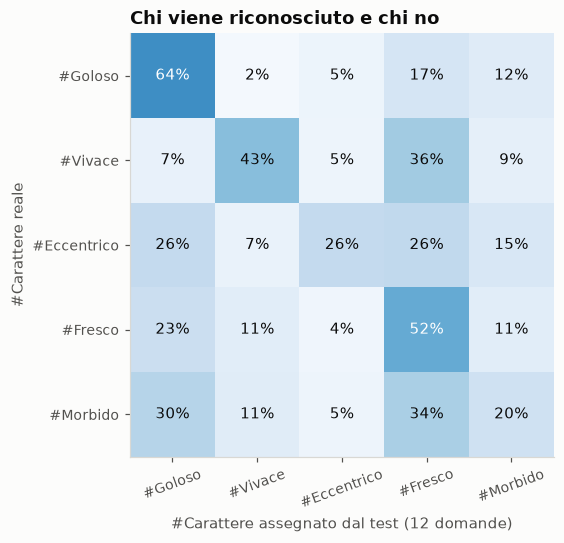

,riconosciuti,attributo che li distingue,dolci con quell'attributo tra le 19 domande
#Goloso,0.64,cioccolato,8
#Vivace,0.43,frutta,6
#Eccentrico,0.26,liquirizia,1
#Fresco,0.52,menta,1
#Morbido,0.20,menta,1


In [13]:
cm = confusion_matrix(y_te, passi[gomito_90]["pred"], normalize="true")
fig, ax = plt.subplots(figsize=(6.4, 5))
ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
for i in range(5):
    for j in range(5):
        ax.text(j, i, f"{cm[i, j]:.0%}", ha="center", va="center", fontsize=10, color="white" if cm[i, j] > 0.5 else "#0b0b0b")
ax.set_xticks(range(5), NOMI, rotation=20); ax.set_yticks(range(5), NOMI)
ax.set_xlabel(f"#Carattere assegnato dal test ({gomito_90} domande)"); ax.set_ylabel("#Carattere reale")
ax.set_title("Chi viene riconosciuto e chi no"); ax.grid(False)
salva(fig, "03_matrice_confusione")
plt.show()
cat_ = pd.read_csv("../data/processed/catalogo.csv").set_index("dolce")
attributo_chiave = {"#Goloso": "cioccolato", "#Vivace": "frutta", "#Eccentrico": "liquirizia", "#Fresco": "menta", "#Morbido": "menta"}
pd.DataFrame({"riconosciuti": np.diag(cm).round(2),
              "attributo che li distingue": [attributo_chiave[n] for n in NOMI],
              "dolci con quell'attributo tra le 19 domande": [int(cat_.loc[DOMANDE_GUSTO, attributo_chiave[n]].sum()) for n in NOMI]},
             index=NOMI)

Il riconoscimento è molto diverso tra profili, e la tabella suggerisce il perché: **un profilo si riconosce bene solo se il serbatoio contiene domande sul suo gusto**.

- **#Goloso (64%) e #Vivace (43%)** sono definiti da cioccolato e frutta, gli attributi più rappresentati tra le 19 domande.
- **#Eccentrico (26%) e #Morbido (20%)** dipendono da liquirizia e menta, e il serbatoio contiene **un solo dolce per ciascuno** (Black Jacks e Mint Juleps).
- **#Fresco (52%)** sembra un'eccezione, perché anche lui dipende dalla menta. Però è il profilo **più numeroso**, e il modello lo assegna "per default" quando le risposte non indicano altro. Una parte del suo riconoscimento viene quindi dalla sua frequenza, non da un'informazione specifica.

È un'indicazione di progettazione concreta: **le domande di un Taste Test vanno scelte per coprire ogni dimensione sensoriale del profilo**, non solo per popolarità o per varietà di prodotto. Una domanda in più sulla menta o sulla liquirizia varrebbe probabilmente più di un'altra domanda sul cioccolato.

## 6. Un test adattivo fa meglio?

Il Taste Test di Vinhood sceglie le domande in base alle risposte precedenti. Simulo questa logica con un **albero decisionale**: ogni nodo è una domanda, e il percorso dipende dalle risposte. Per ogni persona conto quante domande *diverse* le vengono poste davvero.

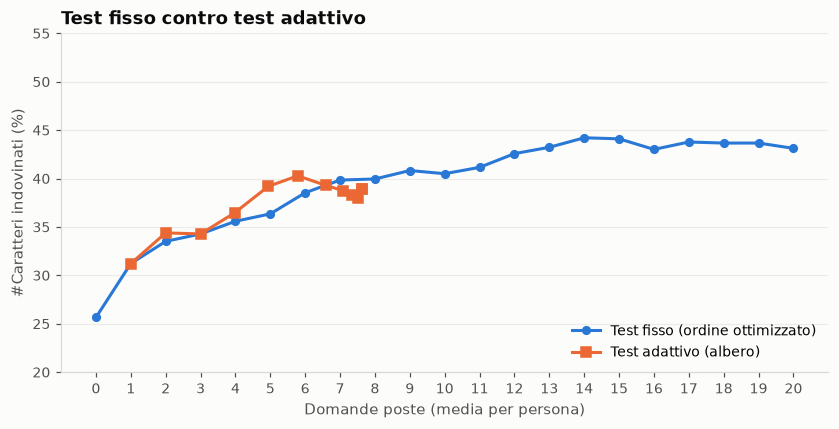

,profondità,domande_medie,accuratezza
0,1,1.000,0.312
1,2,2.000,0.344
2,3,3.000,0.343
3,4,3.977,0.365
4,5,4.941,0.392
5,6,5.785,0.403
6,7,6.587,0.393
7,8,7.079,0.388
8,9,7.347,0.383
9,10,7.511,0.380


In [14]:
domanda_di = {c: q for q, b in BLOCCHI.items() for c in b.columns}
cols_tutte = list(X_tutto.columns)
adattivo = []
for prof in range(1, 13):
    albero = DecisionTreeClassifier(max_depth=prof, min_samples_leaf=30, random_state=SEED).fit(X_tutto.iloc[idx_tr], y_tr)
    percorsi = albero.decision_path(X_tutto.iloc[idx_te])
    feat = albero.tree_.feature
    n_dom = [len({domanda_di[cols_tutte[feat[n]]] for n in percorsi[i].indices if feat[n] >= 0}) for i in range(len(y_te))]
    adattivo.append({"profondità": prof, "domande_medie": np.mean(n_dom),
                     "accuratezza": accuracy_score(y_te, albero.predict(X_tutto.iloc[idx_te]))})
adattivo = pd.DataFrame(adattivo)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(k_ax, acc * 100, marker="o", color=BLU, markersize=5, label="Test fisso (ordine ottimizzato)")
ax.plot(adattivo["domande_medie"], adattivo["accuratezza"] * 100, marker="s", color=ARANCIO, markersize=6, label="Test adattivo (albero)")
ax.set_xlabel("Domande poste (media per persona)"); ax.set_ylabel("#Caratteri indovinati (%)")
ax.set_xticks(k_ax); ax.set_ylim(20, 55)
ax.set_title("Test fisso contro test adattivo"); ax.legend(loc="lower right")
salva(fig, "03_fisso_vs_adattivo")
plt.show()
adattivo.round(3)

**A parità di domande, il test adattivo è leggermente più efficiente**: circa il 40% dei profili indovinati con una media di 6 domande, contro il 38–39% del test fisso con 6 domande.

Però **si ferma lì**. Un singolo albero usa ogni risposta solo per decidere la domanda successiva, mentre il modello del test fisso combina tutte le risposte insieme.

La soluzione migliore nella pratica è probabilmente ibrida: **scegliere le domande in modo adattivo e poi combinare tutte le risposte** in un modello unico.

## 7. Dalla statistica alla decisione: la lunghezza ottimale

Introduco il costo delle domande con un modello semplice:
- partono **1.000 persone**;
- a ogni domanda una quota fissa *r* abbandona il test;
- conta il numero di **#Caratteri corretti consegnati** = persone che completano × accuratezza.

Il tasso di abbandono reale non è nei dati, quindi è un'**ipotesi**, che esploro su un intervallo di valori. Vinhood conosce il proprio valore e può inserirlo direttamente.

Per ogni domanda calcolo anche l'**abbandono di pareggio**: se la domanda *k* fa perdere più di *r\** utenti, conviene toglierla.

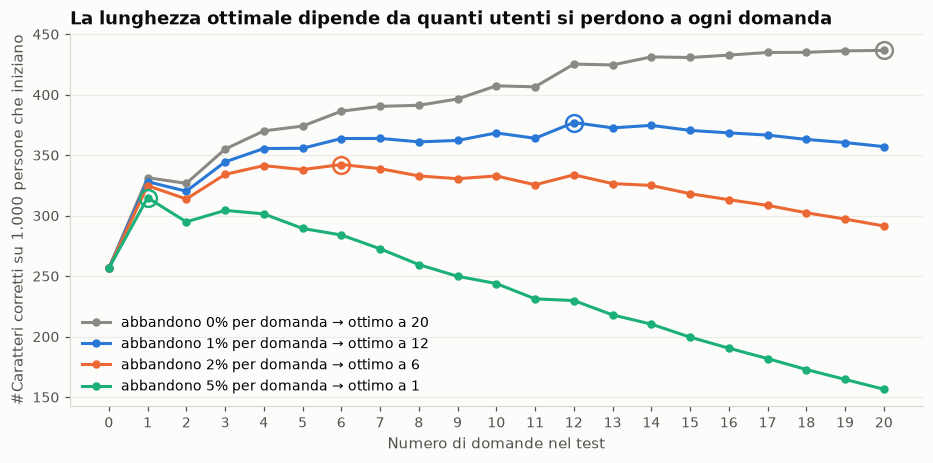

,domanda,accuratezza (CV),abbandono di pareggio r*
k,,,
0,—,25.7%,—
1,Nerds,33.1%,+22.6%
2,100 Grand,32.7%,-1.4%
3,Black Jacks,35.5%,+8.0%
4,Hard Candy,37.0%,+4.1%
5,Peanut M&M's,37.4%,+1.1%
6,Skittles,38.6%,+3.2%
7,Mars,39.0%,+1.0%
8,Necco Wafers,39.1%,+0.2%


In [15]:
pareggio = pd.DataFrame({
    "domanda": ["—"] + [ETICHETTE[q] for q in ordine],
    "accuratezza (CV)": acc_cv.values,
    "abbandono di pareggio r*": [np.nan] + [1 - acc_cv[k - 1] / acc_cv[k] for k in range(1, K + 1)],
}, index=acc_cv.index)
pareggio.index.name = "k"

fig, ax = plt.subplots(figsize=(10, 4.4))
for r, col in zip([0.0, 0.01, 0.02, 0.05], [GRIGIO, BLU, ARANCIO, ACQUA]):
    corretti = 1000 * (1 - r) ** acc_cv.index * acc_cv.values
    ottimo = int(np.argmax(corretti))
    ax.plot(acc_cv.index, corretti, marker="o", markersize=4.5, color=col, label=f"abbandono {r:.0%} per domanda → ottimo a {ottimo}")
    ax.plot(ottimo, corretti[ottimo], marker="o", markersize=11, markerfacecolor="none", markeredgecolor=col, markeredgewidth=1.6)
ax.set_xticks(acc_cv.index)
ax.set_xlabel("Numero di domande nel test"); ax.set_ylabel("#Caratteri corretti su 1.000 persone che iniziano")
ax.set_title("La lunghezza ottimale dipende da quanti utenti si perdono a ogni domanda")
ax.legend(loc="lower left")
salva(fig, "03_lunghezza_ottimale")
plt.show()
pareggio.style.format({"accuratezza (CV)": "{:.1%}", "abbandono di pareggio r*": "{:+.1%}"}, na_rep="—")

La lunghezza ottimale **dipende fortemente dall'abbandono per domanda**:

| Abbandono per domanda | Lunghezza ottimale |
|---|---|
| 0% (nessuno abbandona) | 20 domande, ma oltre 12–14 il guadagno è minimo |
| 1% | 12 domande |
| 2% | 6 domande |
| 5% | 1 domanda |

La tabella dell'abbandono di pareggio lo dice domanda per domanda:
- la 1ª domanda vale la pena anche perdendo oltre il 20% degli utenti;
- la 3ª fino all'8%;
- intorno alla 10ª–12ª il pareggio scende a 3–4%;
- dalla 15ª in poi è sotto l'1%, quindi basta un abbandono minimo per renderle dannose.

Con un abbandono dell'1–2%, plausibile per domande rapide e divertenti, l'ottimo cade tra 6 e 12 domande.

## 8. Robustezza: e se avessi diviso il catalogo in un altro modo?

Il serbatoio di domande dipende dalla divisione casuale del catalogo (notebook 02). Ripeto **l'intera pipeline** (profili, ordine delle domande, curva) su altre due divisioni.

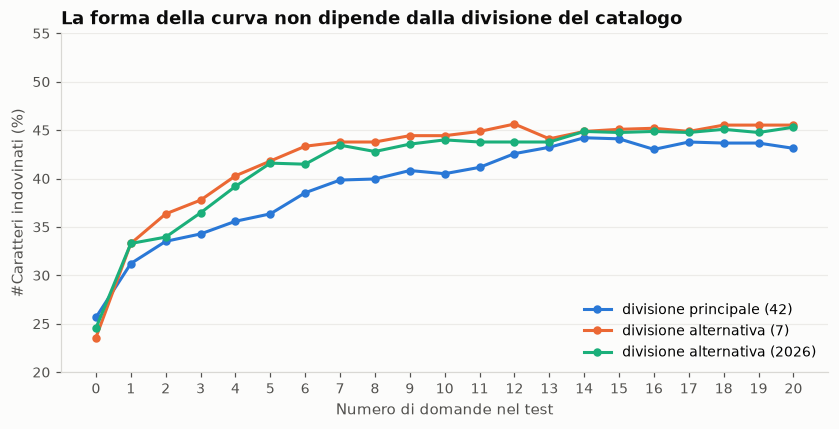

,0 domande,1 domanda,12 domande,20 domande,posizione dell'età nell'ordine
divisione principale (42),0.256550,0.312227,0.425764,0.431223,14.0
divisione alternativa (7),0.235808,0.332969,0.456332,0.455240,9.0
divisione alternativa (2026),0.245633,0.332969,0.437773,0.453057,9.0


In [16]:
from sklearn.cluster import KMeans
cat = pd.read_csv("../data/processed/catalogo.csv").set_index("dolce")
ATTR = ["cioccolato", "frutta", "menta", "arachidi", "caramello", "liquirizia"]
ORDINE_ATTR = ["liquirizia", "menta", "arachidi", "caramello", "cioccolato", "frutta"]
cat["principale"] = [next((a for a in ORDINE_ATTR if cat.loc[d, a]), "nessuno") for d in cat.index]

def dividi(seed, quota=2/3):
    r_ = np.random.default_rng(seed); P_, Q_ = [], []
    for g in ORDINE_ATTR + ["nessuno"]:
        dd = list(r_.permutation(cat.index[cat["principale"] == g])); n = int(round(len(dd) * quota))
        P_ += dd[:n]; Q_ += dd[n:]
    return P_, Q_

def pipeline(seed):
    P_, Q_ = dividi(seed)
    rel = M[P_].sub(M[P_].mean(axis=1), axis=0)
    S_ = pd.DataFrame({a: rel[[d for d in P_ if cat.loc[d, a]]].mean(axis=1) for a in ATTR}).fillna(0)
    y_ = KMeans(5, n_init=50, random_state=SEED).fit_predict(((S_ - S_.mean()) / S_.std()).values)
    blocchi = {d: codifica_gusto(M[d]) for d in Q_} | {c: BLOCCHI[c] for c in CONTESTO}
    tr, te = train_test_split(np.arange(len(y_)), test_size=0.2, stratify=y_, random_state=SEED)
    def X_(qs): return pd.concat([blocchi[q] for q in qs], axis=1)
    def ll_(qs): return -cross_val_score(LogisticRegression(C=C, max_iter=3000), X_(qs).iloc[tr], y_[tr], cv=cv, scoring="neg_log_loss").mean()
    ordine_, rest = [], list(blocchi)
    while rest:
        b = min(rest, key=lambda q: ll_(ordine_ + [q])); ordine_.append(b); rest.remove(b)
    base_ = (y_[te] == np.bincount(y_[tr]).argmax()).mean()
    accs = [base_] + [accuracy_score(y_[te], LogisticRegression(C=C, max_iter=3000).fit(X_(ordine_[:k]).iloc[tr], y_[tr]).predict(X_(ordine_[:k]).iloc[te]))
                      for k in range(1, len(ordine_) + 1)]
    return pd.Series(accs), ordine_

robust = {"divisione principale (42)": pd.Series(acc)}
ordini_alt = {}
for seme in [7, 2026]:
    robust[f"divisione alternativa ({seme})"], ordini_alt[seme] = pipeline(seme)

fig, ax = plt.subplots(figsize=(9, 4))
for (nome, s), col in zip(robust.items(), [BLU, ARANCIO, ACQUA]):
    ax.plot(s.index, s.values * 100, marker="o", markersize=4.5, color=col, label=nome)
ax.set_xticks(range(0, K + 1)); ax.set_ylim(20, 55)
ax.set_xlabel("Numero di domande nel test"); ax.set_ylabel("#Caratteri indovinati (%)")
ax.set_title("La forma della curva non dipende dalla divisione del catalogo"); ax.legend(loc="lower right")
salva(fig, "03_robustezza_divisioni")
plt.show()

tab_rob = pd.DataFrame({n: {"0 domande": s[0], "1 domanda": s[1], f"{gomito_90} domande": s[gomito_90], f"{K} domande": s[K],
                            "posizione dell'età nell'ordine": None} for n, s in robust.items()}).T
tab_rob.loc["divisione principale (42)", "posizione dell'età nell'ordine"] = 1 + ordine.index("eta")
for seme, o in ordini_alt.items():
    tab_rob.loc[f"divisione alternativa ({seme})", "posizione dell'età nell'ordine"] = 1 + o.index("eta")
tab_rob

Rifacendo **tutto** da capo con divisioni diverse del catalogo (profili, serbatoio di domande, ordine, curva), la forma resta la stessa:
- circa 24–26% senza domande;
- 31–33% con una domanda;
- 43–46% con 12;
- al massimo un punto e mezzo in più fino a 20 domande.

L'età entra sempre dopo molte domande di gusto (9ª–14ª posizione).

Il risultato non dipende dalla particolare divisione del catalogo che ho usato.

## 9. Conclusioni

**Cosa dicono i dati** (4.579 persone, 57 dolci, valutazione su persone e prodotti mai visti):

1. **Ogni domanda aiuta, ma sempre meno.** Il gomito si trova tra **8 e 12 domande**: lì il test raggiunge il 90% del suo potenziale e non è statisticamente distinguibile dal test completo.
2. **Quali domande conta quanto quante.** Con domande scelte in modo ottimale bastano circa metà delle domande che servirebbero scegliendole a caso. Le domande migliori **dividono il pubblico** (i fruttati); quelle sui dolci amati da tutti servono a poco.
3. **Le domande sul gusto battono quelle demografiche.** L'età vale quanto una domanda di gusto mediocre ed entra nel test solo dopo 13 domande di gusto.
4. **Un profilo si riconosce bene solo se il test lo "interroga".** Eccentrico e Morbido, legati a liquirizia e menta, sono riconosciuti poco: il serbatoio ha una sola domanda per ciascun attributo.
5. **Il Carattere comunica, il modello diretto consiglia.** Per raccomandare prodotti conviene usare le risposte direttamente: l'AUC passa da 0,63 a 0,74 rispetto ai consigli dedotti dal profilo.
6. **La lunghezza ottimale dipende dall'abbandono**: 12 domande all'1% per domanda, 6 al 2%.

**Cosa farei con questi risultati:**

- **Misurare l'abbandono reale per ogni domanda** e usare il modello della sezione 7 per fissare la lunghezza del test, categoria per categoria.
- **Progettare il serbatoio di domande per copertura sensoriale.** Ogni attributo che definisce un profilo deve avere almeno 2–3 domande.
- **Valutare ogni nuova domanda con il suo guadagno marginale**, con intervalli di confidenza, prima di inserirla nel test.
- **Separare i due usi**: il #Carattere per la comunicazione, un modello diretto per le raccomandazioni.

**Limiti.**
- Campione nordamericano e auto-selezionato (lettori di BoingBoing), contesto Halloween.
- Scala binaria gioia/delusione, più povera di una scala 1–5.
- L'abbandono è un'ipotesi, non un dato osservato.
- I profili sono costruiti sugli stessi rispondenti del train: la replica su persone nuove è nel notebook 04.

→ **Notebook 04:** il test progettato sul 2015 funziona su persone nuove, due anni dopo?